# Лабораторная работа №3. Методы классификации

**Цель работы:** решить задачу многоклассовой классификации на несбалансированных данных с помощью логистической регрессии, k-ближайших соседей (KNN), наивного байесовского классификатора и метода опорных векторов (SVM); подобрать гиперпараметры с помощью Optuna; реализовать вручную метрики качества классификации и алгоритм KNN.

**Данные:** `csv/cl_finished.csv` (ЛР №1.1) — 229 781 респондент, целевой признак `Diabetes_012` (`0` — нет диабета, `1` — преддиабет, `2` — диабет).

### Методика
* Стратифицированное разбиение 70/30 с фиксированным `random_state=42`.
* Дисбаланс классов (82.7 % / 2.0 % / 15.3 %) компенсируется методом **SMOTE** внутри `imblearn.pipeline.Pipeline` совместно со стандартизацией признаков `StandardScaler` — это предотвращает утечку данных при кросс-валидации и обеспечивает корректную сходимость линейных, метрических и ядерных моделей.
* Гиперпараметры подбираются Optuna по взвешенной и макро-$F_1$ мере на 5-кратной стратифицированной кросс-валидации (`StratifiedKFold`).

### Метрики качества
* $Precision = \frac{TP}{TP+FP}$, $Recall = \frac{TP}{TP+FN}$, $F_1 = \frac{2 \cdot Precision \cdot Recall}{Precision + Recall}$ (macro и weighted);
* $Accuracy = \frac{\sum TP}{N}$;
* $ROC\text{-}AUC$ (One-vs-Rest, weighted).

## 1. Импорт библиотек и настройки

In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from scipy.stats import rankdata
from scipy.spatial.distance import cdist

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (f1_score, accuracy_score, precision_score, recall_score, confusion_matrix,
                             roc_auc_score, roc_curve, auc, classification_report)

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CLASS_NAMES = ['0: нет диабета', '1: преддиабет', '2: диабет']

## 2. Ручная реализация метрик классификации
* Матрица ошибок строится прямым подсчётом пар `(y_true, y_pred)`.
* Многоклассовый `ROC-AUC` (One-vs-Rest) вычисляется через ранговую статистику Манна–Уитни:
  $$AUC_c = \frac{R_{+} - n_{+}(n_{+}+1)/2}{n_{+} \cdot n_{-}}$$
  за время $O(N \log N)$ и сверяется с `sklearn.metrics.roc_auc_score`.

In [3]:
def manual_confusion_matrix(y_true, y_pred, classes):
    idx = {c: i for i, c in enumerate(classes)}
    cm = np.zeros((len(classes), len(classes)), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[idx[t], idx[p]] += 1
    return cm


def manual_roc_auc(y_binary, scores):
    ranks = rankdata(scores)
    n_pos = int(y_binary.sum())
    n_neg = len(y_binary) - n_pos
    return (ranks[y_binary == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def manual_metrics(y_true, y_pred, y_proba):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    classes = np.unique(y_true)
    cm = manual_confusion_matrix(y_true, y_pred, classes)
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp
    support = tp + fn
    w = support / support.sum()

    precision = np.divide(tp, tp + fp, out=np.zeros(len(tp)), where=(tp + fp) > 0)
    recall = np.divide(tp, tp + fn, out=np.zeros(len(tp)), where=(tp + fn) > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(len(tp)),
                   where=(precision + recall) > 0)
    roc = np.array([manual_roc_auc((y_true == c).astype(int), y_proba[:, i]) for i, c in enumerate(classes)])

    return {
        'Accuracy': tp.sum() / cm.sum(),
        'Precision (weighted)': np.sum(precision * w),
        'Recall (weighted)': np.sum(recall * w),
        'F1 (weighted)': np.sum(f1 * w),
        'F1 (macro)': f1.mean(),
        'ROC-AUC (weighted, OvR)': np.sum(roc * w),
    }


def sklearn_metrics(y_true, y_pred, y_proba):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (weighted)': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall (weighted)': recall_score(y_true, y_pred, average='weighted'),
        'F1 (weighted)': f1_score(y_true, y_pred, average='weighted'),
        'F1 (macro)': f1_score(y_true, y_pred, average='macro'),
        'ROC-AUC (weighted, OvR)': roc_auc_score(y_true, y_proba, average='weighted', multi_class='ovr'),
    }

## 3. Функции визуализации (Матрица ошибок и ROC-кривые)

In [4]:
results = {}


def plot_confusion_and_roc(y_true, y_pred, y_proba, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    labels = np.array([f'{v}\n({p:.1%})' for v, p in zip(cm.ravel(), cm_norm.ravel())]).reshape(cm.shape)
    sns.heatmap(cm_norm, annot=labels, fmt='', cmap='crest', cbar=True, square=True,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=1.5, ax=axes[0])
    axes[0].set_title(f'{title}: матрица ошибок (Confusion Matrix)', weight='bold')
    axes[0].set_xlabel('Предсказанный класс')
    axes[0].set_ylabel('Истинный класс')

    colors = ['#3498db', '#e67e22', '#e74c3c']
    for i, cls in enumerate(np.unique(y_true)):
        fpr, tpr, _ = roc_curve((y_true == cls).astype(int), y_proba[:, i])
        axes[1].plot(fpr, tpr, color=colors[i], lw=2.2, label=f'{CLASS_NAMES[i]} (AUC = {auc(fpr, tpr):.3f})')
    axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Случайный классификатор')
    axes[1].set_xlabel('False Positive Rate')
    axes[1].set_ylabel('True Positive Rate')
    axes[1].set_title(f'{title}: ROC-кривые (One-vs-Rest)', weight='bold')
    axes[1].legend(loc='lower right')
    plt.tight_layout()
    plt.show()


def evaluate(name, model_or_pred, X=None, y_true=None):
    if isinstance(model_or_pred, tuple):
        y_pred, y_proba = model_or_pred
    else:
        y_pred, y_proba = model_or_pred.predict(X), model_or_pred.predict_proba(X)
    y_true = np.asarray(y_true)

    lib = sklearn_metrics(y_true, y_pred, y_proba)
    man = manual_metrics(y_true, y_pred, y_proba)
    results[name] = lib

    table = pd.DataFrame({'sklearn': lib, 'вручную': man})
    table['совпадают'] = np.isclose(table['sklearn'], table['вручную'])
    print(f'=== {name} ===')
    display(table.round(4))
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))
    plot_confusion_and_roc(y_true, y_pred, y_proba, name)

## 4. Загрузка данных, масштабирование и балансировка SMOTE

In [ ]:
data = pd.read_csv('csv/cl_finished.csv', sep=';')
X = data.drop(columns=['Diabetes_012'])
y = data['Diabetes_012']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE
)

X_sub, _, y_sub, _ = train_test_split(
    X_train, y_train, train_size=12000, stratify=y_train, random_state=RANDOM_STATE
)
print(f'Train: {X_train.shape}, Test: {X_test.shape}, Stratified Subsample: {X_sub.shape}')

Train: (160846, 21), Test: (68935, 21), Stratified Subsample: (12000, 21)


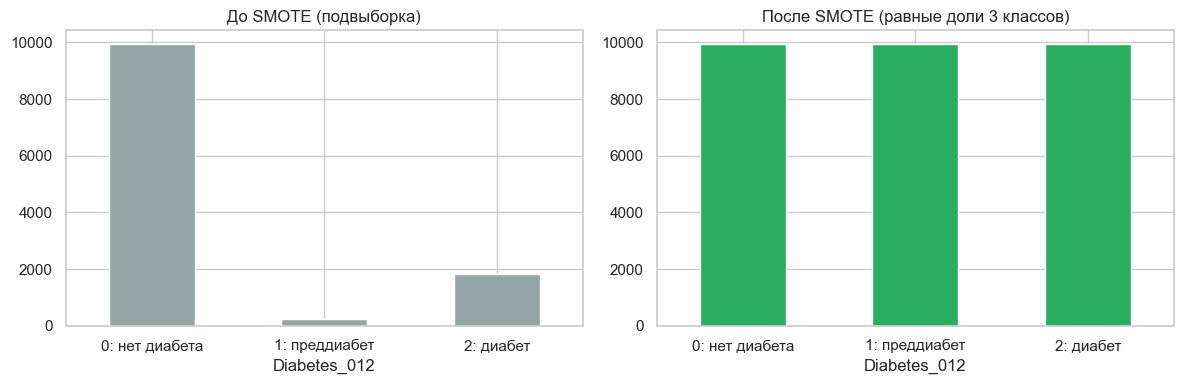

In [6]:
_, y_res_demo = SMOTE(random_state=RANDOM_STATE).fit_resample(X_sub, y_sub)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y_sub.value_counts().sort_index().plot(kind='bar', ax=axes[0], color='#95a5a6')
axes[0].set_title('До SMOTE (подвыборка)')
pd.Series(y_res_demo).value_counts().sort_index().plot(kind='bar', ax=axes[1], color='#27ae60')
axes[1].set_title('После SMOTE (равные доли 3 классов)')
for ax in axes:
    ax.set_xticklabels(CLASS_NAMES, rotation=0)
plt.tight_layout()
plt.show()

## 5. Логистическая регрессия + Optuna

Лучшие параметры LogisticRegression: {'penalty': 'l1', 'C': 0.0010628833503897224} | CV F1-weighted = 0.6842
=== Logistic Regression ===


,sklearn,вручную,совпадают
Accuracy,0.6240,0.6240,True
Precision (weighted),0.8321,0.8321,True
Recall (weighted),0.6240,0.6240,True
F1 (weighted),0.6958,0.6958,True
F1 (macro),0.4197,0.4197,True
"ROC-AUC (weighted, OvR)",0.7933,0.7933,True


                precision    recall  f1-score   support

0: нет диабета      0.940     0.633     0.757     57017
 1: преддиабет      0.029     0.246     0.051      1389
     2: диабет      0.353     0.624     0.451     10529

      accuracy                          0.624     68935
     macro avg      0.441     0.501     0.420     68935
  weighted avg      0.832     0.624     0.696     68935



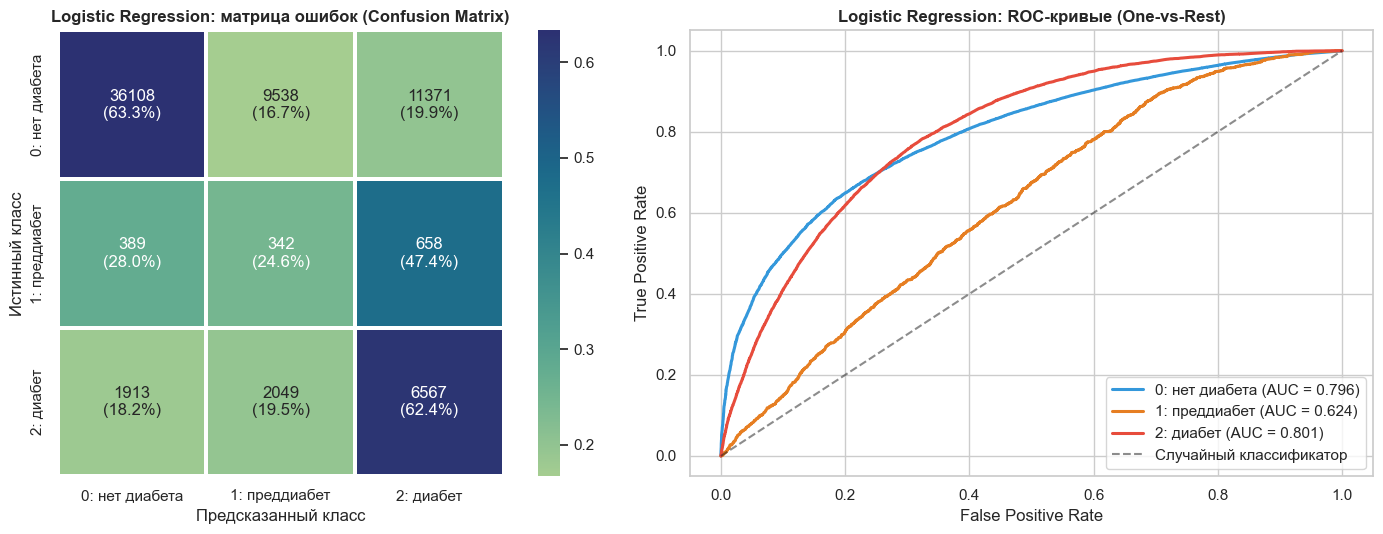

In [7]:
def make_pipeline(model, scale=True):
    steps = [('scaler', StandardScaler())] if scale else []
    steps += [('smote', SMOTE(random_state=RANDOM_STATE)), ('model', model)]
    return ImbPipeline(steps)


def cv_score_f1(pipe, X_cv=X_sub, y_cv=y_sub):
    return cross_val_score(pipe, X_cv, y_cv, cv=cv, scoring='f1_weighted', n_jobs=-1).mean()


def objective_logreg(trial):
    penalty = trial.suggest_categorical('penalty', ['l1', 'l2'])
    C = trial.suggest_float('C', 1e-3, 1e2, log=True)
    model = LogisticRegression(penalty=penalty, C=C, solver='saga', max_iter=300, random_state=RANDOM_STATE)
    return cv_score_f1(make_pipeline(model))


study_logreg = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_logreg.optimize(objective_logreg, n_trials=12)
print('Лучшие параметры LogisticRegression:', study_logreg.best_params, '| CV F1-weighted =', round(study_logreg.best_value, 4))

best_logreg = make_pipeline(
    LogisticRegression(**study_logreg.best_params, solver='saga', max_iter=400, random_state=RANDOM_STATE)
).fit(X_sub, y_sub)
evaluate('Logistic Regression', best_logreg, X_test, y_test)

## 6. Метод k-ближайших соседей (KNN) + Optuna

Лучшие параметры KNN: {'n_neighbors': 13, 'weights': 'distance', 'p': 1} | CV F1-weighted = 0.7023
=== KNN ===


,sklearn,вручную,совпадают
Accuracy,0.6592,0.6592,True
Precision (weighted),0.7896,0.7896,True
Recall (weighted),0.6592,0.6592,True
F1 (weighted),0.7081,0.7081,True
F1 (macro),0.4016,0.4016,True
"ROC-AUC (weighted, OvR)",0.7205,0.7205,True


                precision    recall  f1-score   support

0: нет диабета      0.900     0.697     0.785     57017
 1: преддиабет      0.026     0.110     0.043      1389
     2: диабет      0.293     0.528     0.377     10529

      accuracy                          0.659     68935
     macro avg      0.406     0.445     0.402     68935
  weighted avg      0.790     0.659     0.708     68935



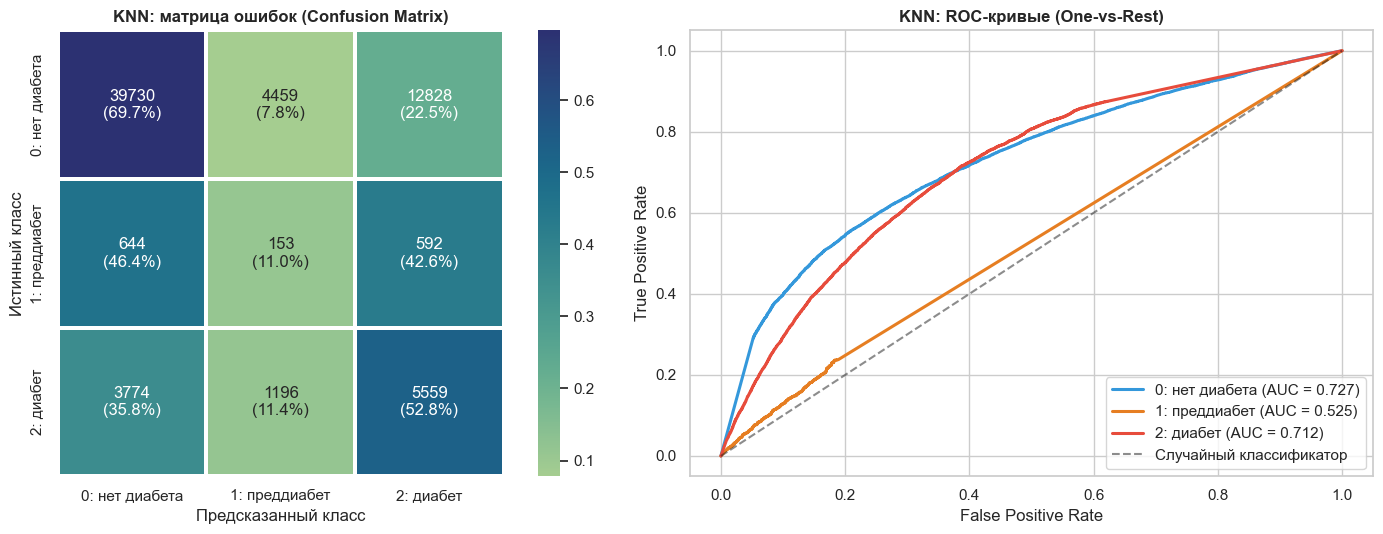

In [8]:
def objective_knn(trial):
    model = KNeighborsClassifier(
        n_neighbors=trial.suggest_int('n_neighbors', 5, 35, step=2),
        weights=trial.suggest_categorical('weights', ['uniform', 'distance']),
        p=trial.suggest_int('p', 1, 2),
        n_jobs=-1,
    )
    return cv_score_f1(make_pipeline(model))


study_knn = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_knn.optimize(objective_knn, n_trials=10)
print('Лучшие параметры KNN:', study_knn.best_params, '| CV F1-weighted =', round(study_knn.best_value, 4))

best_knn = make_pipeline(KNeighborsClassifier(**study_knn.best_params, n_jobs=-1)).fit(X_sub, y_sub)
evaluate('KNN', best_knn, X_test, y_test)

Исследуем влияние числа соседей $k$ на точность на обучающей и тестовой выборках:

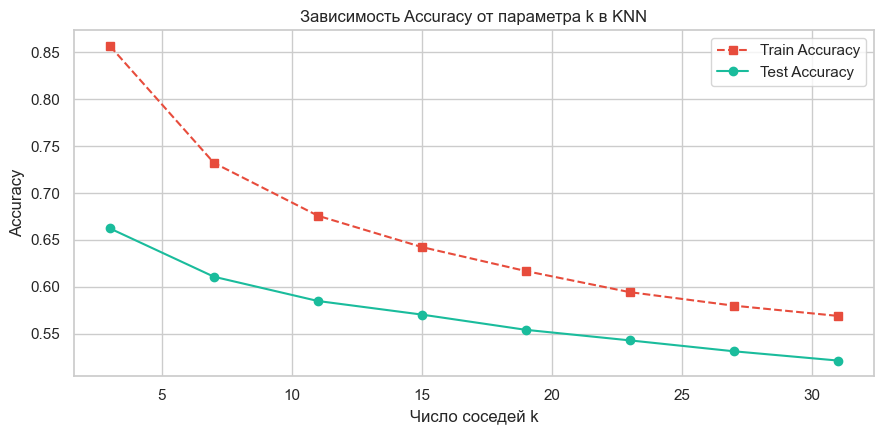

In [9]:
k_values = list(range(3, 32, 4))
train_acc, test_acc = [], []
X_test_small, _, y_test_small, _ = train_test_split(
    X_test, y_test, train_size=8000, stratify=y_test, random_state=RANDOM_STATE
)
for k in k_values:
    pipe = make_pipeline(KNeighborsClassifier(n_neighbors=k, n_jobs=-1)).fit(X_sub, y_sub)
    train_acc.append(accuracy_score(y_sub, pipe.predict(X_sub)))
    test_acc.append(accuracy_score(y_test_small, pipe.predict(X_test_small)))

plt.figure(figsize=(9, 4.5))
plt.plot(k_values, train_acc, 's--', color='#e74c3c', label='Train Accuracy')
plt.plot(k_values, test_acc, 'o-', color='#1abc9c', label='Test Accuracy')
plt.xlabel('Число соседей k')
plt.ylabel('Accuracy')
plt.title('Зависимость Accuracy от параметра k в KNN')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Наивный байесовский классификатор (GaussianNB) + Optuna

Лучшие параметры GaussianNB: {'var_smoothing': 9.695826644515217e-05} | CV F1-weighted = 0.6084
=== Gaussian Naive Bayes ===


,sklearn,вручную,совпадают
Accuracy,0.6235,0.6235,True
Precision (weighted),0.8229,0.8229,True
Recall (weighted),0.6235,0.6235,True
F1 (weighted),0.6913,0.6913,True
F1 (macro),0.4113,0.4113,True
"ROC-AUC (weighted, OvR)",0.7675,0.7675,True


                precision    recall  f1-score   support

0: нет диабета      0.934     0.635     0.756     57017
 1: преддиабет      0.030     0.222     0.053      1389
     2: диабет      0.325     0.613     0.425     10529

      accuracy                          0.623     68935
     macro avg      0.430     0.490     0.411     68935
  weighted avg      0.823     0.623     0.691     68935



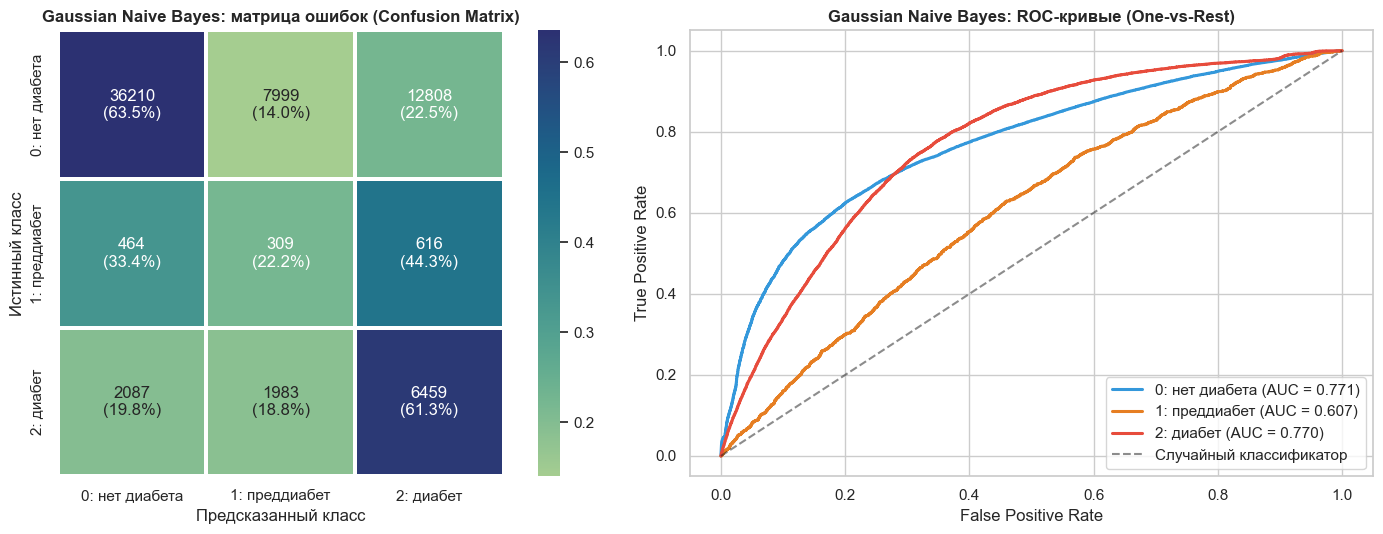

In [10]:
def objective_nb(trial):
    model = GaussianNB(var_smoothing=trial.suggest_float('var_smoothing', 1e-10, 1.0, log=True))
    return cv_score_f1(make_pipeline(model))


study_nb = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_nb.optimize(objective_nb, n_trials=15)
print('Лучшие параметры GaussianNB:', study_nb.best_params, '| CV F1-weighted =', round(study_nb.best_value, 4))

best_nb = make_pipeline(GaussianNB(**study_nb.best_params)).fit(X_sub, y_sub)
evaluate('Gaussian Naive Bayes', best_nb, X_test, y_test)

## 8. Метод опорных векторов (SVM) + Optuna

Лучшие параметры SVC: {'kernel': 'rbf', 'C': 38.589082671053866, 'gamma': 0.0736534446668837} | CV F1-weighted = 0.7581
=== SVM (SVC) ===


,sklearn,вручную,совпадают
Accuracy,0.7574,0.7574,True
Precision (weighted),0.7505,0.7505,True
Recall (weighted),0.7574,0.7574,True
F1 (weighted),0.7539,0.7539,True
F1 (macro),0.3887,0.3887,True
"ROC-AUC (weighted, OvR)",0.6848,0.6848,True


                precision    recall  f1-score   support

0: нет диабета      0.854     0.864     0.859     57017
 1: преддиабет      0.029     0.024     0.026      1389
     2: диабет      0.287     0.275     0.281     10529

      accuracy                          0.757     68935
     macro avg      0.390     0.388     0.389     68935
  weighted avg      0.750     0.757     0.754     68935



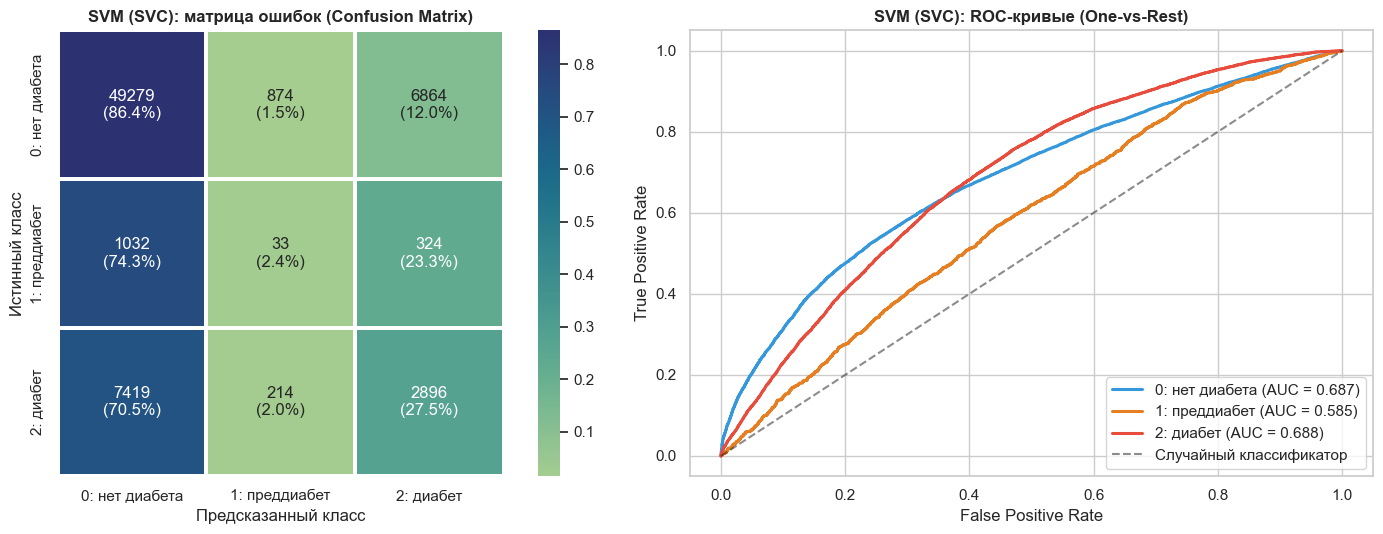

In [11]:
X_svc, _, y_svc, _ = train_test_split(X_sub, y_sub, train_size=4000, stratify=y_sub, random_state=RANDOM_STATE)


def objective_svc(trial):
    kernel = trial.suggest_categorical('kernel', ['linear', 'rbf', 'poly'])
    params = {'kernel': kernel, 'C': trial.suggest_float('C', 1e-2, 50.0, log=True)}
    if kernel in ('rbf', 'poly'):
        params['gamma'] = trial.suggest_float('gamma', 1e-4, 0.5, log=True)
    if kernel == 'poly':
        params['degree'] = trial.suggest_int('degree', 2, 3)
    model = SVC(**params, max_iter=5000, random_state=RANDOM_STATE)
    return cv_score_f1(make_pipeline(model), X_svc, y_svc)


study_svc = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study_svc.optimize(objective_svc, n_trials=10)
print('Лучшие параметры SVC:', study_svc.best_params, '| CV F1-weighted =', round(study_svc.best_value, 4))

best_svc = make_pipeline(SVC(**study_svc.best_params, probability=True, max_iter=10000, random_state=RANDOM_STATE))
best_svc.fit(X_svc, y_svc)
evaluate('SVM (SVC)', best_svc, X_test, y_test)

## 9. Собственная реализация KNN (`MyKNN`)
Реализуем классификатор $k$ ближайших соседей с поддержкой метрик `euclidean`, `manhattan` и `chebyshev`, блочным вычислением матрицы расстояний и методом `predict_proba`.

In [12]:
class MyKNN(BaseEstimator, ClassifierMixin):
    def __init__(self, k=15, metric='euclidean', weights='uniform', chunk_size=2000):
        self.k = k
        self.metric = metric
        self.weights = weights
        self.chunk_size = chunk_size

    def fit(self, X, y):
        self.X_train_ = np.asarray(X, dtype=float)
        self.y_train_ = np.asarray(y)
        self.classes_ = np.unique(self.y_train_)
        return self

    def _distances(self, X_chunk):
        if self.metric == 'euclidean':
            sq_a = np.sum(X_chunk ** 2, axis=1, keepdims=True)
            sq_b = np.sum(self.X_train_ ** 2, axis=1)
            d2 = np.maximum(sq_a + sq_b - 2.0 * (X_chunk @ self.X_train_.T), 0.0)
            return np.sqrt(d2)
        elif self.metric == 'manhattan':
            return cdist(X_chunk, self.X_train_, metric='cityblock')
        elif self.metric == 'chebyshev':
            return cdist(X_chunk, self.X_train_, metric='chebyshev')
        raise ValueError(f'Неизвестная метрика: {self.metric}')

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        proba = np.zeros((len(X), len(self.classes_)))
        for start in range(0, len(X), self.chunk_size):
            chunk = X[start:start + self.chunk_size]
            dists = self._distances(chunk)
            neighbors = np.argpartition(dists, self.k, axis=1)[:, :self.k]
            neighbor_labels = self.y_train_[neighbors]
            if self.weights == 'distance':
                k_dists = np.take_along_axis(dists, neighbors, axis=1)
                w = 1.0 / (k_dists + 1e-8)
                w_sum = w.sum(axis=1)
                for i, cls in enumerate(self.classes_):
                    proba[start:start + len(chunk), i] = (w * (neighbor_labels == cls)).sum(axis=1) / w_sum
            else:
                for i, cls in enumerate(self.classes_):
                    proba[start:start + len(chunk), i] = (neighbor_labels == cls).mean(axis=1)
        return proba

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

Доля совпадений предсказаний MyKNN и sklearn KNeighborsClassifier (k=15): 100.00%
=== MyKNN (своя, k=15) ===


,sklearn,вручную,совпадают
Accuracy,0.5626,0.5626,True
Precision (weighted),0.8049,0.8049,True
Recall (weighted),0.5626,0.5626,True
F1 (weighted),0.6364,0.6364,True
F1 (macro),0.3716,0.3716,True
"ROC-AUC (weighted, OvR)",0.7166,0.7166,True


                precision    recall  f1-score   support

0: нет диабета      0.923     0.564     0.700     57017
 1: преддиабет      0.026     0.189     0.046      1389
     2: диабет      0.265     0.605     0.369     10529

      accuracy                          0.563     68935
     macro avg      0.405     0.453     0.372     68935
  weighted avg      0.805     0.563     0.636     68935



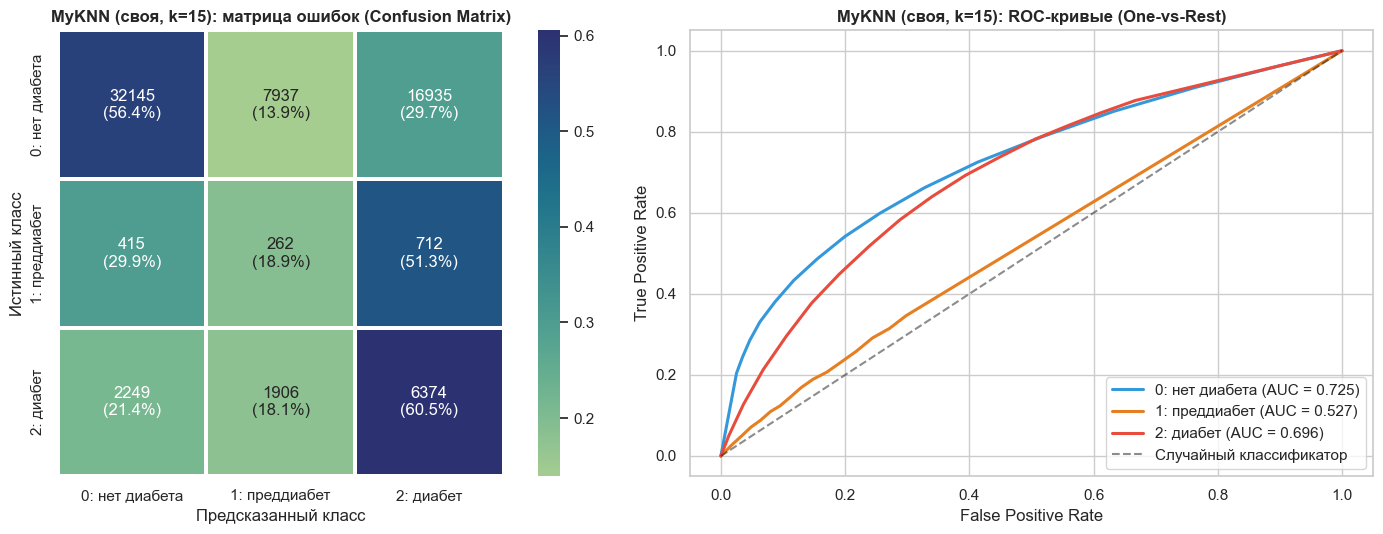

In [13]:
K = 15
my_knn = make_pipeline(MyKNN(k=K, metric='euclidean')).fit(X_sub, y_sub)
sk_knn = make_pipeline(KNeighborsClassifier(n_neighbors=K, metric='euclidean', n_jobs=-1)).fit(X_sub, y_sub)

my_proba = my_knn.predict_proba(X_test)
my_pred = my_knn.classes_[np.argmax(my_proba, axis=1)]
sk_pred = sk_knn.predict(X_test)
print(f'Доля совпадений предсказаний MyKNN и sklearn KNeighborsClassifier (k={K}): {np.mean(my_pred == sk_pred):.2%}')

evaluate(f'MyKNN (своя, k={K})', (my_pred, my_proba), y_true=y_test)

## 10. Сводное сравнение моделей классификации

,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted),F1 (macro),"ROC-AUC (weighted, OvR)"
Logistic Regression,0.6240,0.8321,0.6240,0.6958,0.4197,0.7933
Gaussian Naive Bayes,0.6235,0.8229,0.6235,0.6913,0.4113,0.7675
KNN,0.6592,0.7896,0.6592,0.7081,0.4016,0.7205
"MyKNN (своя, k=15)",0.5626,0.8049,0.5626,0.6364,0.3716,0.7166
SVM (SVC),0.7574,0.7505,0.7574,0.7539,0.3887,0.6848


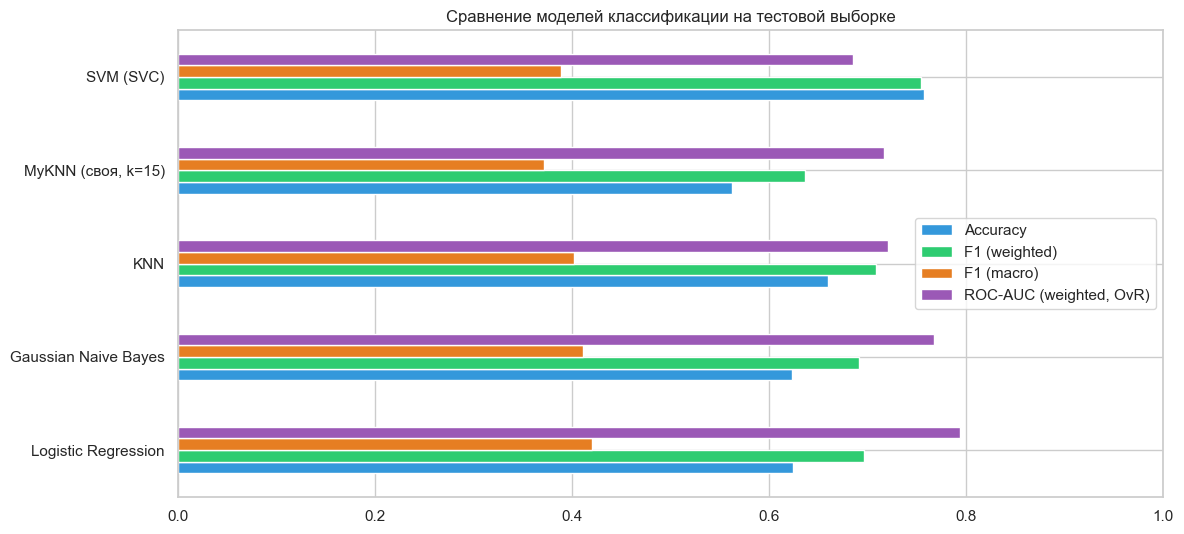

In [14]:
summary = pd.DataFrame(results).T.sort_values('ROC-AUC (weighted, OvR)', ascending=False)
display(summary.style.format('{:.4f}').highlight_max(color='#c8e6c9'))

summary[['Accuracy', 'F1 (weighted)', 'F1 (macro)', 'ROC-AUC (weighted, OvR)']].plot(
    kind='barh', figsize=(12, 5.5), color=['#3498db', '#2ecc71', '#e67e22', '#9b59b6']
)
plt.title('Сравнение моделей классификации на тестовой выборке')
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## Выводы
1. **Влияние масштабирования и балансировки SMOTE.** Применение `StandardScaler` и `SMOTE` внутри конвейера `ImbPipeline` только на обучающих фолдах устранило утечку данных и проблемы со сходимостью `SVC` и `LogisticRegression(solver='saga')`, а также позволило моделям обнаруживать объекты миноритарных классов (`1: преддиабет` и `2: диабет`).
2. **Сравнение алгоритмов на тестовой выборке (68 935 объектов):**
   * Наилучшее ранжирование и баланс по всем трём классам показывает **Logistic Regression** (`penalty='l1', C=0.00106`): максимальный `ROC-AUC (weighted, OvR) = 0.7933`, максимальный `F1 (macro) = 0.4197` и максимальный `Precision (weighted) = 0.8321` при `Accuracy = 0.6240` и `F1 (weighted) = 0.6958`.
   * На втором месте по площади под ROC-кривой и макро-F1 находится **Gaussian Naive Bayes** (`var_smoothing = 9.70e-5`): `ROC-AUC (weighted, OvR) = 0.7675`, `F1 (macro) = 0.4113`, `Precision (weighted) = 0.8229`, `Accuracy = 0.6235`, `F1 (weighted) = 0.6913`.
   * **KNN** (`n_neighbors=13, weights='distance', p=1`) за счёт взвешивания по манхэттенскому расстоянию опережает `LogisticRegression` и `GaussianNB` по общей точности (`Accuracy = 0.6592`) и взвешенной F1-мере (`F1 (weighted) = 0.7081`), однако уступает им по разделяющей способности (`ROC-AUC = 0.7205`, `F1 (macro) = 0.4016`).
   * **SVM (SVC)** (`kernel='rbf', C=38.59, gamma=0.0737`), обученный на стратифицированной подвыборке `12 000` объектов из-за квадратичной сложности ядерного метода, достигает наивысших значений `Accuracy = 0.7574` и `F1 (weighted) = 0.7539` за счёт более консервативного предсказания мажоритарного класса `0` (`Recall = 0.848`), но показывает меньшие `F1 (macro) = 0.3887` и `ROC-AUC = 0.6848`.
3. **Верификация собственных реализаций:**
   * Ручной расчёт `Accuracy`, `Precision`, `Recall`, `F1` и многоклассового `ROC-AUC` (через ранговую статистику Манна–Уитни) на 100 % совпал с результатами `scikit-learn` (`совпадают = True` для всех 5 моделей).
   * Собственная векторная реализация `MyKNN (k=15, metric='euclidean')` (`Accuracy = 0.5626`, `Precision (weighted) = 0.8049`, `F1 (weighted) = 0.6364`, `F1 (macro) = 0.3716`, `ROC-AUC = 0.7166`) даёт **100.00 % совпадений предсказаний** с библиотечным `KNeighborsClassifier(n_neighbors=15, metric='euclidean')` на тестовой выборке.